In [23]:
from pathlib import Path
import urllib.request

seed=42
root=Path.cwd()
data_dir=root / "data"
data_dir.mkdir(parents=True, exist_ok=True)
csv_path=data_dir / "url_dataset.csv"
data_url=(
    "https://media.githubusercontent.com/media/"
    "SahinMuhammetAbdullah/urldataset/"
    "f5f51e340d426c37c25ce9fe34d621cb382cb037/malicious_phish.csv"
)

if not csv_path.exists():
    print("Downloading the public URL dataset (about 46 MB)...")
    urllib.request.urlretrieve(data_url, csv_path)
print(f"Dataset saved at: {csv_path}")

Dataset saved at: d:\ML\Projects\RetailPriceForecast\data\url_dataset.csv


In [24]:
import pandas as pd
raw=pd.read_csv(csv_path, usecols=["url", "type"])
print("Downloaded dataset shape:", raw.shape)
print(raw.head().to_string(index=False))

Downloaded dataset shape: (640120, 2)
                                                                                                                                                                                                                                        url       type
                                                                                                                                                                                                                           br-icloud.com.br   phishing
                                                                                                                                                                                                        mp3raid.com/music/krizz_kaliko.html     benign
                                                                                                                                                                                                            bopsecrets.org/re

In [25]:
classes={"benign", "phishing", "malware", "defacement"}
raw["url"]=raw["url"].astype("string").str.strip()
raw["type"]=raw["type"].astype("string").str.strip().str.lower()
raw=raw.dropna(subset=["url", "type"])
raw=raw.loc[raw["url"].str.len().between(1, 4096)]
# Ignore malformed labels caused by unquoted commas in a small number of source rows.
raw=raw.loc[raw["type"].isin(classes)]
raw=raw.drop_duplicates(subset="url", keep="first")
raw["label"]=(raw["type"] != "benign").map(
    {False: "benign", True: "harmful"}
)
df=raw[["url", "type", "label"]].reset_index(drop=True)
if len(df) < 3000:
    raise ValueError(f"Expected a large URL dataset; only {len(df)} valid rows remain.")
assert set(df["type"].unique()) == classes
assert set(df["label"].unique()) == {"benign", "harmful"}
df.to_csv(csv_path, index=False)
print(f"Cleaned dataset saved to CSV: {csv_path}")
print("Cleaned URL rows:", f"{len(df):,}")
print("Binary label counts:")
print(df["label"].value_counts().to_string())
print("Source label counts:")
print(df["type"].value_counts().to_string())

Cleaned dataset saved to CSV: d:\ML\Projects\RetailPriceForecast\data\url_dataset.csv
Cleaned URL rows: 640,120
Binary label counts:
label
benign     427856
harmful    212264
Source label counts:
type
benign        427856
defacement     94913
phishing       93706
malware        23645


In [26]:
df=pd.read_csv(csv_path)
print("Saved training dataset shape:", df.shape)
print(df.head().to_string(index=False))

Saved training dataset shape: (640120, 3)
                                                                                                                                                                                                                                        url       type   label
                                                                                                                                                                                                                           br-icloud.com.br   phishing harmful
                                                                                                                                                                                                        mp3raid.com/music/krizz_kaliko.html     benign  benign
                                                                                                                                                                                                 

In [27]:
from sklearn.model_selection import train_test_split

url_tr, url_te, y_tr, y_te=train_test_split(
    df["url"],
    df["label"],
    test_size=0.20,
    random_state=seed,
    stratify=df["label"],
)
print("Training rows:", f"{len(url_tr):,}")
print("Test rows:", f"{len(url_te):,}")
print("Training labels:")
print(y_tr.value_counts().to_string())
print("Test labels:")
print(y_te.value_counts().to_string())

Training rows: 512,096
Test rows: 128,024
Training labels:
label
benign     342285
harmful    169811
Test labels:
label
benign     85571
harmful    42453


In [28]:
import ipaddress
import math
import re
from collections import Counter
from urllib.parse import urlsplit

bad_terms=(
    "login", "verify", "account", "secure", "update", "password", "signin",
    "confirm", "banking", "wallet", "webscr", "support", "invoice",
)
short_hosts={
    "bit.ly", "tinyurl.com", "t.co", "goo.gl", "is.gd", "buff.ly",
    "ow.ly", "rebrand.ly", "cutt.ly", "shorturl.at",
}

def entropy(text):
    if not text:
        return 0.0
    counts=Counter(text)
    length=len(text)
    return -sum((count / length) * math.log2(count / length)
                for count in counts.values())

def url_feats(value):
    url=str(value).strip()
    low=url.lower()
    parsed=url if re.match(r"^[a-z][a-z0-9+.-]*://", url, re.I) else f"//{url}"
    try:
        parts=urlsplit(parsed)
        host=(parts.hostname or "").lower()
        port=parts.port
    except ValueError:
        parts=urlsplit("")
        host=""
        port=None

    ip_host=host.strip("[]")
    try:
        ipaddress.ip_address(ip_host)
        is_ip=1
    except ValueError:
        is_ip=0
    labels=[part for part in host.split(".") if part]
    digits=sum(character.isdigit() for character in url)
    term_n=sum(term in low for term in bad_terms)
    return {
        "url_len": len(url),
        "host_len": len(host),
        "path_len": len(parts.path),
        "query_len": len(parts.query),
        "frag_len": len(parts.fragment),
        "dots": url.count("."),
        "hyphens": url.count("-"),
        "underscores": url.count("_"),
        "slashes": url.count("/"),
        "questions": url.count("?"),
        "equals": url.count("="),
        "ats": url.count("@"),
        "amps": url.count("&"),
        "percents": url.count("%"),
        "digits": digits,
        "digit_ratio": digits / max(len(url), 1),
        "subdomains": max(0, len(labels) - 2),
        "path_depth": len([part for part in parts.path.split("/") if part]),
        "is_ip": is_ip,
        "is_https": int(low.startswith("https://")),
        "is_http": int(low.startswith("http://")),
        "is_puny": int("xn--" in host),
        "has_port": int(port is not None),
        "has_frag": int(bool(parts.fragment)),
        "bad_term_n": term_n,
        "is_short": int(host in short_hosts),
        "entropy": entropy(low),
    }

x_tr=pd.DataFrame(
    [url_feats(url) for url in url_tr],
    index=url_tr.index,
)
x_te=pd.DataFrame(
    [url_feats(url) for url in url_te],
    index=url_te.index,
    columns=x_tr.columns,
)
y_tr=y_tr.loc[x_tr.index]
y_te=y_te.loc[x_te.index]
print("ANN input features:", x_tr.shape[1])
print("Training feature matrix:", x_tr.shape)
print("Test feature matrix:", x_te.shape)

ANN input features: 27
Training feature matrix: (512096, 27)
Test feature matrix: (128024, 27)


In [29]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model=make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=0.001,
        batch_size=4096,
        learning_rate_init=0.001,
        max_iter=100,
        early_stopping=True,
        n_iter_no_change=10,
        random_state=seed,
        verbose=True,
    ),
)
print(model)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('mlpclassifier',
                 MLPClassifier(alpha=0.001, batch_size=4096,
                               early_stopping=True, hidden_layer_sizes=(64, 32),
                               max_iter=100, random_state=42, verbose=True))])


Iteration 1, loss = 0.39830949
Validation score: 0.883734
Iteration 2, loss = 0.23908212
Validation score: 0.909100
Iteration 3, loss = 0.20356801
Validation score: 0.929174
Iteration 4, loss = 0.17962275
Validation score: 0.934622
Iteration 5, loss = 0.16351569
Validation score: 0.939895
Iteration 6, loss = 0.15268666
Validation score: 0.943507
Iteration 7, loss = 0.14571104
Validation score: 0.947510
Iteration 8, loss = 0.14086615
Validation score: 0.948252
Iteration 9, loss = 0.13735195
Validation score: 0.949268
Iteration 10, loss = 0.13505641
Validation score: 0.949385
Iteration 11, loss = 0.13301873
Validation score: 0.948506
Iteration 12, loss = 0.13141844
Validation score: 0.949932
Iteration 13, loss = 0.13005958
Validation score: 0.949072
Iteration 14, loss = 0.12877163
Validation score: 0.949307
Iteration 15, loss = 0.12775793
Validation score: 0.949248
Iteration 16, loss = 0.12687915
Validation score: 0.950186
Iteration 17, loss = 0.12596177
Validation score: 0.950596
Iterat

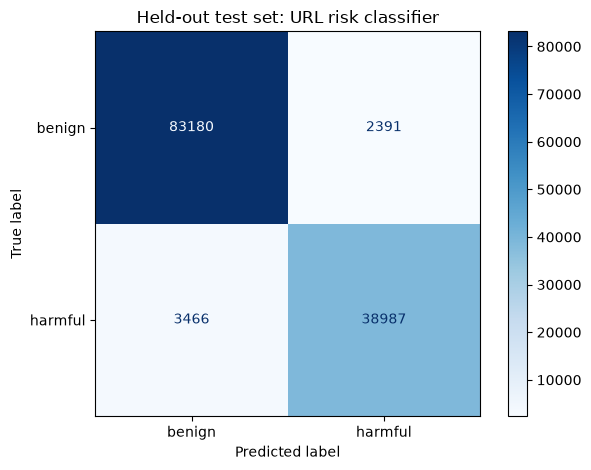

In [30]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    roc_auc_score,
)

model.fit(x_tr, y_tr)
pred=model.predict(x_te)
harm_i=list(model.classes_).index("harmful")
harm_p=model.predict_proba(x_te)[:, harm_i]

print(f"Accuracy: {accuracy_score(y_te, pred):.3f}")
print(f"Harmful-class ROC AUC: {roc_auc_score(y_te == 'harmful', harm_p):.3f}")
print(classification_report(y_te, pred, digits=3, zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_te, pred, labels=["benign", "harmful"], cmap="Blues"
)
plt.title("Held-out test set: URL risk classifier")
plt.tight_layout()
plt.show()

In [31]:
import joblib

def predict_url(url):
    if not isinstance(url, str) or not url.strip():
        raise ValueError("Enter a non-empty URL string.")
    row=pd.DataFrame([url_feats(url)], columns=x_tr.columns)
    probs=model.predict_proba(row)[0]
    risk=float(probs[harm_i])
    return {
        "prediction": "harmful" if risk >= 0.5 else "benign",
        "harmful_probability": risk,
        "warning": "Lexical model estimate only; not a guarantee of safety.",
    }

# Replace this example with a URL string you want to inspect. It is not visited.

predict_url("https://example.com/account")

model_path=root / "url_model.joblib"
joblib.dump(
    {
        "model": model,
        "feature_columns": list(x_tr.columns),
        "labels": ["benign", "harmful"],
        "training_rows": len(x_tr),
        "test_rows": len(x_te),
        "seed": seed,
    },
    model_path,
)
print(f"Saved trained ANN model: {model_path}")

Saved trained ANN model: d:\ML\Projects\RetailPriceForecast\url_model.joblib
